Relative pitch function extractor

From 2-bar MIDI segments, convert the 2nd bar into a relative pitch function.

In [1]:
# Imports section
import numpy as np
from scipy.signal import butter, filtfilt
from music21 import converter, note
import matplotlib.pyplot as plt

In [2]:
# Definition of the path to MIDI file
midi_file_path = "C:/Users/cristinj/OneDrive - Universitetet i Oslo/Documents/Project1/melodic-contour-generation-based-on-sketches/irish_tunes_dataset/Cooley's_0_2bars_1.midi"

In [3]:
# Definition of arrays
onsets = []
pitches = []

In [4]:
# Extract the notes from MIDI file
score = converter.parse(midi_file_path)

# Get only the 1st bar
score = score.measure(1)
score = score.flat.notes

for n in score:
    if isinstance(n, note.Note):
        onsets.append(n.offset)
        pitches.append(n.pitch.midi)

print(onsets)
print(pitches)

[0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 3.5]
[64, 71, 71, 69, 71, 64, 71]


c:\Users\cristinj\AppData\Local\anaconda3\envs\env\lib\site-packages\music21\stream\base.py:3675: Music21DeprecationWarning: .flat is deprecated.  Call .flatten() instead
  return self.iter().getElementsByClass(classFilterList)


C:\Users\cristinj\AppData\Local\Temp\ipykernel_20300\3014874281.py:1: StreamIteratorInefficientWarning: show is not defined on StreamIterators. Call .stream() first for efficiency
  score.show()
c:\Users\cristinj\AppData\Local\anaconda3\envs\env\lib\site-packages\music21\musicxml\m21ToXml.py:428: MusicXMLWarning: <music21.stream.Score 0x1678278e230> is not well-formed; see isWellFormedNotation()
  warnings.warn(f'{sc} is not well-formed; see isWellFormedNotation()',


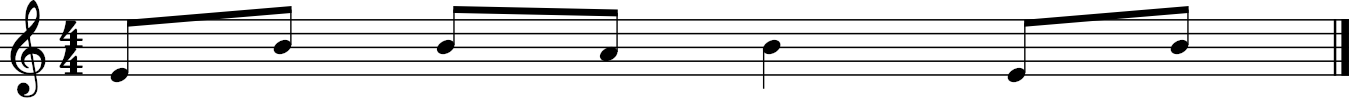

In [5]:
score.show()

In [6]:
# Quantize onsets
positions_per_bar = 48 # decided in the paper
measeure_length = 4 # time signature is 4/4, so 4 beats per measure

# Get relative time inside the measure
norm_onsets = np.mod(onsets, measeure_length) / measeure_length
#print(norm_onsets)

# Map to 48-step grid
quant_onsets = np.round(norm_onsets * positions_per_bar).astype(int)
#print(quant_onsets)

In [7]:
# Compute relative pitch function

# Definition of the constant variables
num_points = 512
filter_cutoff = 1/50
filter_order = 5 # not in the paper, but 5 is a typical value for how steep the roll-off is

# Piecewise-linear interpolation
x = np.linspace(quant_onsets.min(), quant_onsets.max(), num_points)
y = np.interp(x, quant_onsets, pitches)

# Low-pass Butterworth filtering
# to smooth the linear interpolation
b, a = butter(filter_order, filter_cutoff, btype='low')
y_smooth = filtfilt(b, a, y)

# Normalization
# Find midpoint in the curve range
pitch_range = y_smooth.max() - y_smooth.min()
middle_val = y_smooth.min() + pitch_range/2

# Substract midpoint and divide by 12
# 12 because 12 semitones = 1 octave
frp = (y_smooth - middle_val) / 12.0

C:\Users\cristinj\AppData\Local\Temp\ipykernel_20300\3961382056.py:1: StreamIteratorInefficientWarning: show is not defined on StreamIterators. Call .stream() first for efficiency
  score.show()
c:\Users\cristinj\AppData\Local\anaconda3\envs\env\lib\site-packages\music21\musicxml\m21ToXml.py:428: MusicXMLWarning: <music21.stream.Score 0x16782941720> is not well-formed; see isWellFormedNotation()
  warnings.warn(f'{sc} is not well-formed; see isWellFormedNotation()',


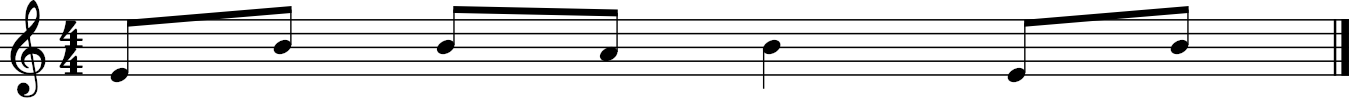

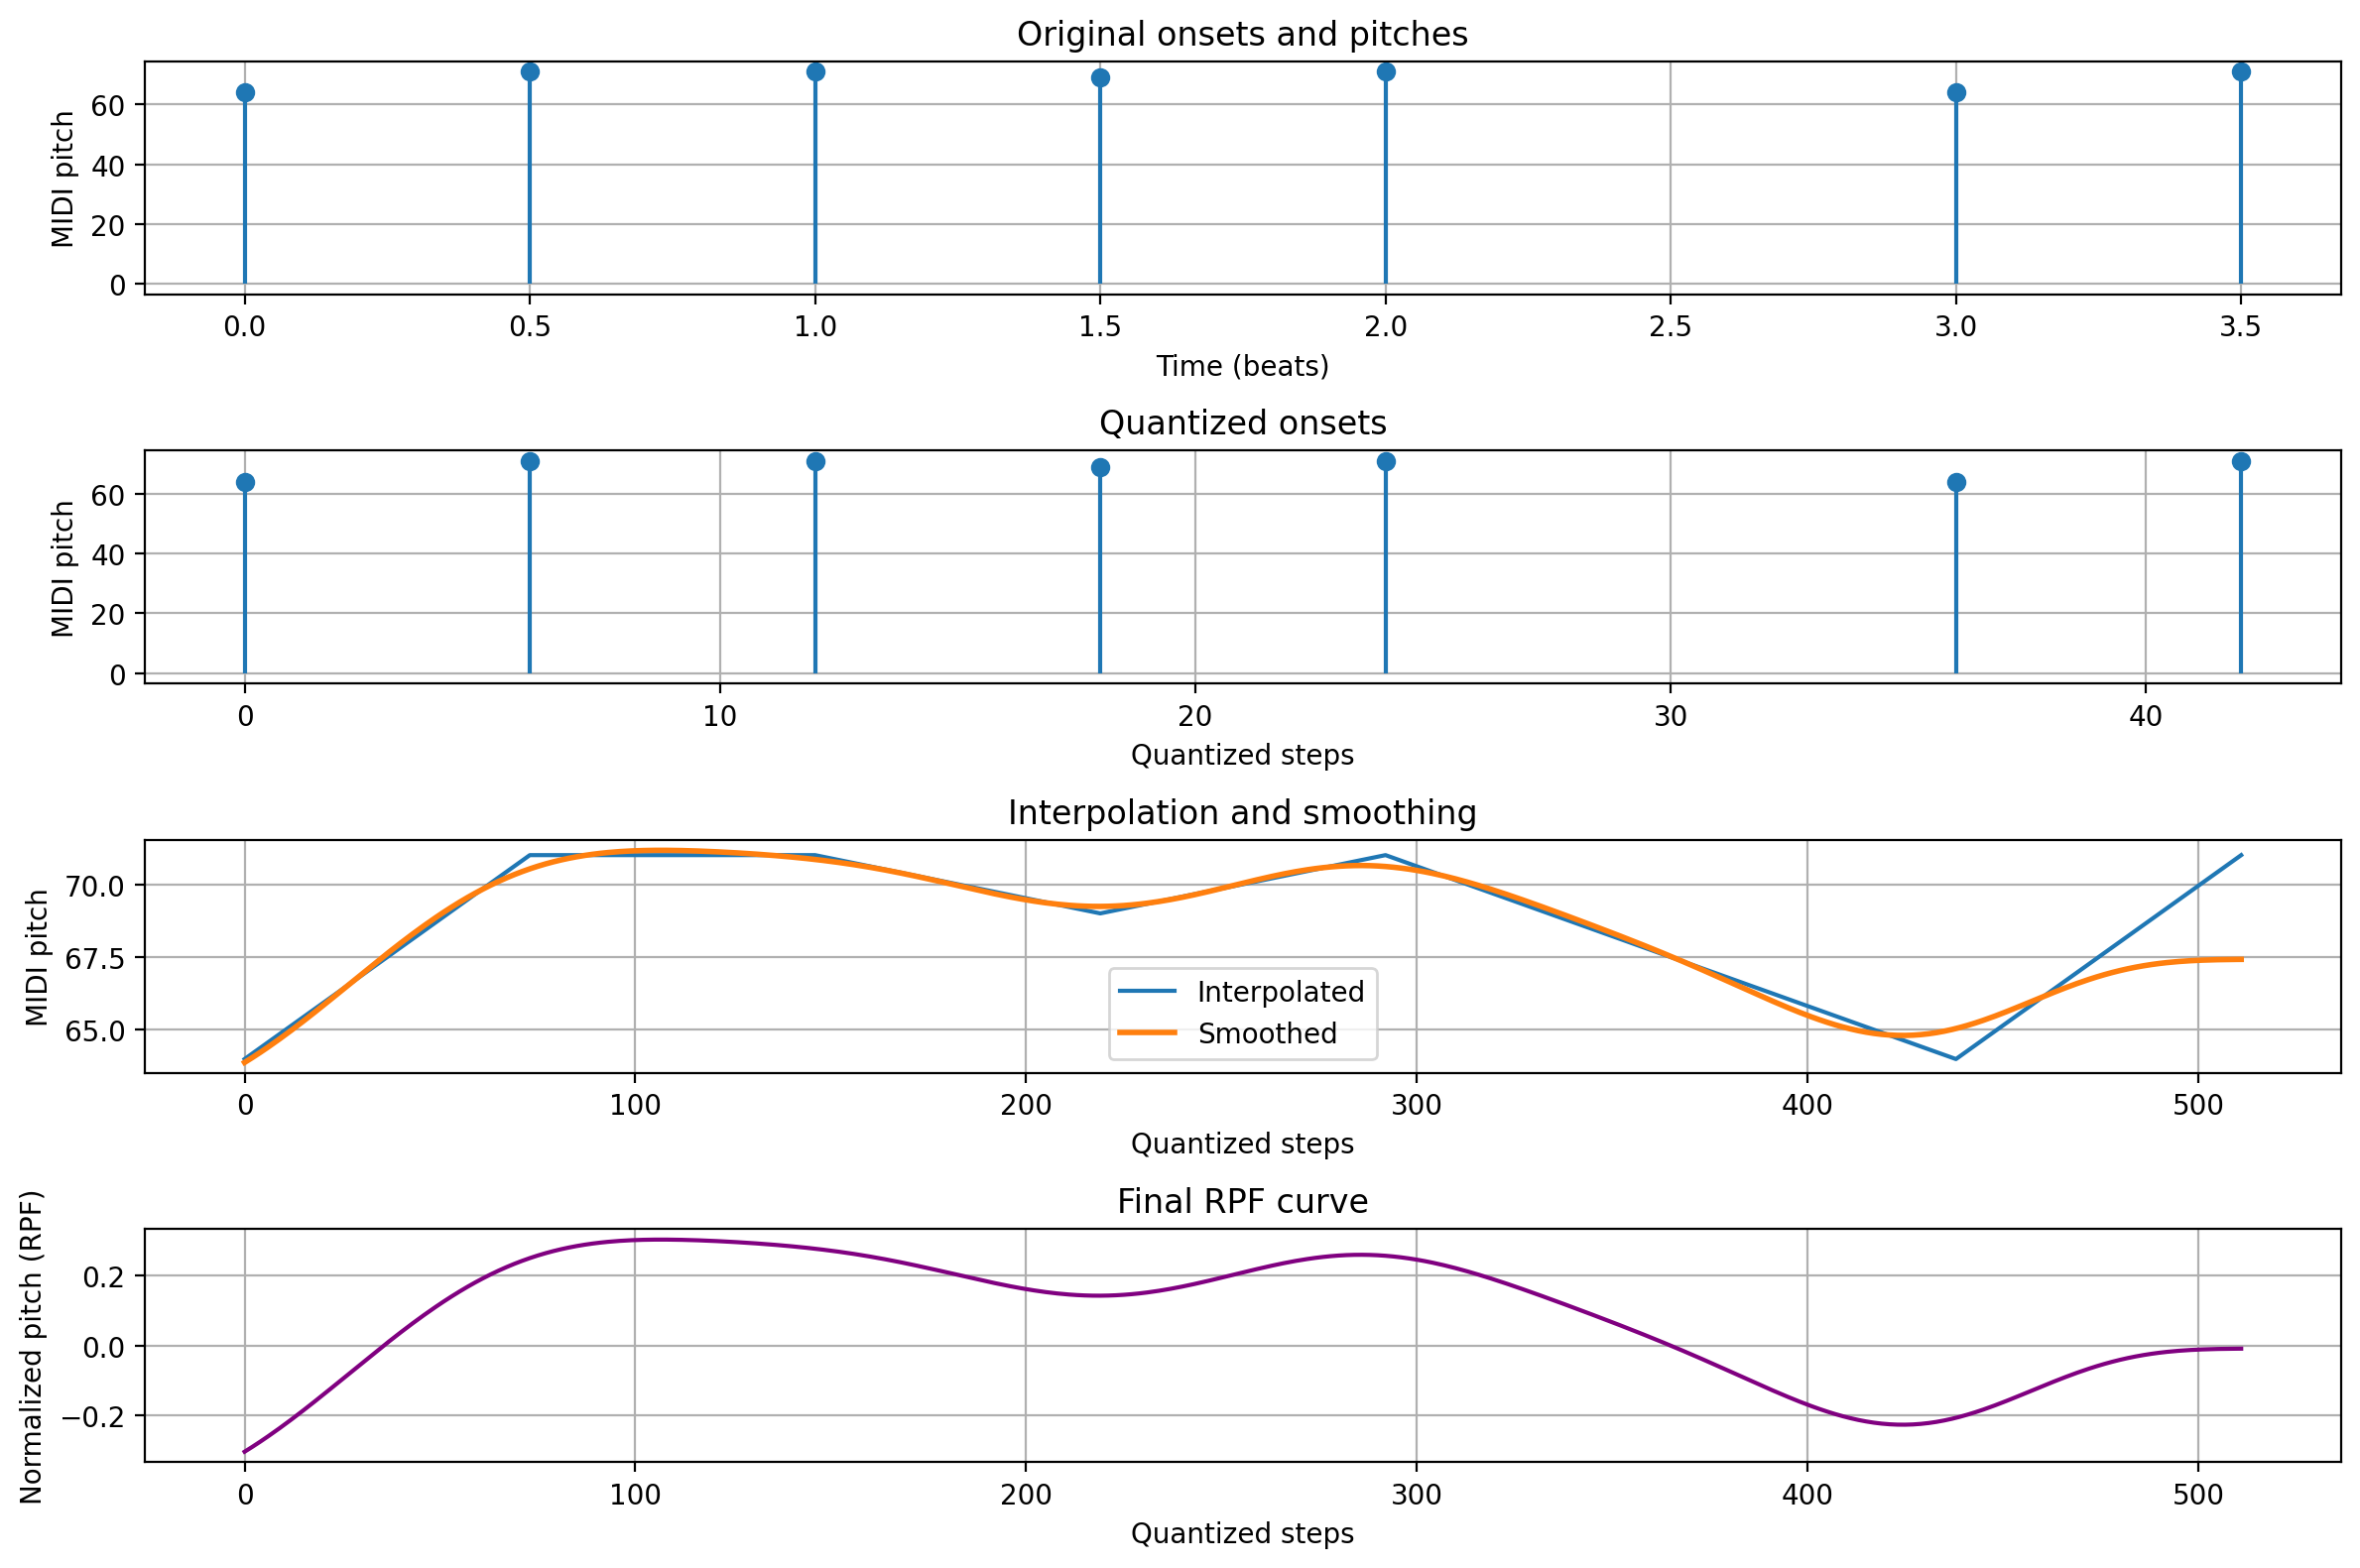

In [8]:
score.show()

plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.stem(onsets, pitches, basefmt=" ")
plt.title("Original onsets and pitches")
plt.xlabel("Time (beats)")
plt.ylabel("MIDI pitch")
plt.grid(True)

plt.subplot(4, 1, 2)
plt.stem(quant_onsets, pitches, basefmt=" ")
plt.title("Quantized onsets")
plt.xlabel("Quantized steps")
plt.ylabel("MIDI pitch")
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(y, label='Interpolated')
plt.plot(y_smooth, label='Smoothed', linewidth=2)
plt.title("Interpolation and smoothing")
plt.xlabel("Quantized steps")
plt.ylabel("MIDI pitch")
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(frp, color='purple')
plt.title("Final RPF curve")
plt.xlabel("Quantized steps")
plt.ylabel("Normalized pitch (RPF)")
plt.grid(True)

plt.tight_layout()
plt.show()

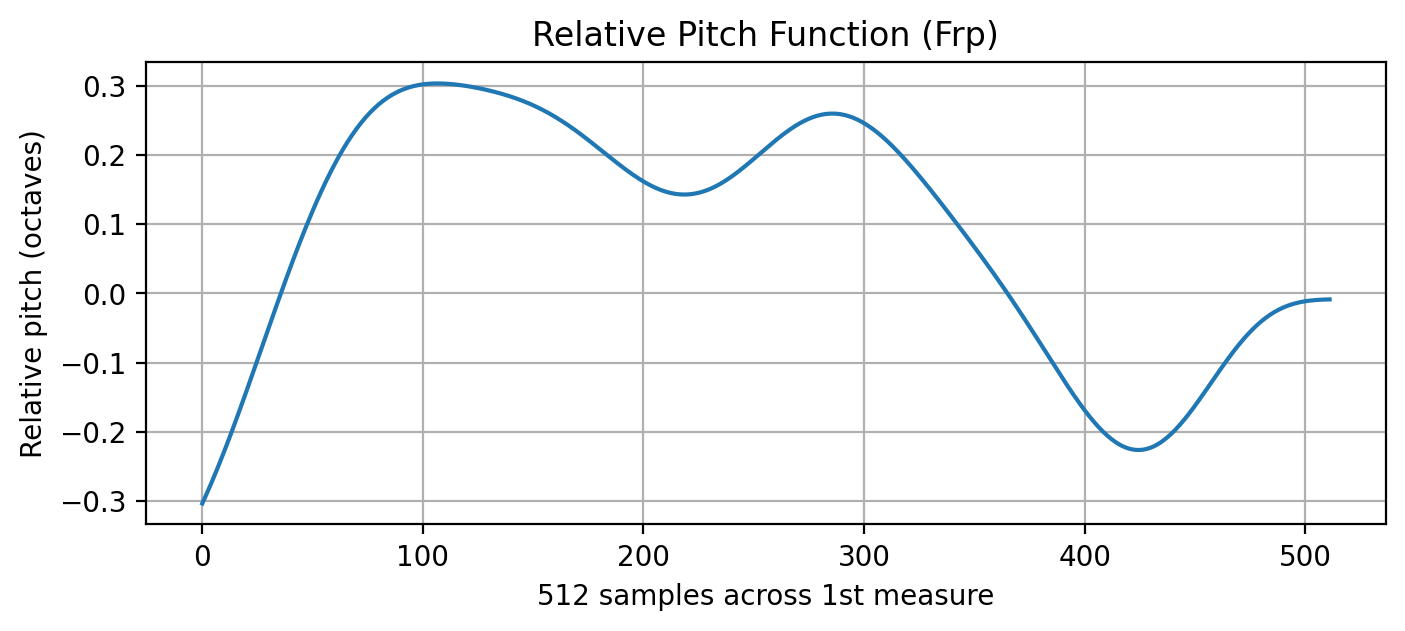

In [9]:
plt.figure(figsize=(8, 3))
plt.plot(frp)
plt.title("Relative Pitch Function (Frp)")
plt.xlabel("512 samples across 1st measure")
plt.ylabel("Relative pitch (octaves)")
plt.grid(True)
plt.show()